# Chapter 08 답안 양식. 작은 데이터 분석 프로젝트 완성하기

> 이 내용을 `chapter08.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보

- 이름: 박재선
- GitHub ID: lilypark0930-lab
- 작성일: 2026.11.04
- 최종 제출 URL: https://github.com/lilypark0930-lab/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb



## 1. 프로젝트 질문

### 분석 질문

1. 카테고리별 completed 주문 기준 금액은 어떻게 다른가?
2. 월별 completed 주문 기준 금액과 주문 수는 어떻게 변하는가?
3. completed 주문 기준 구매 금액이 높은 고객은 어떤 특징을 보이는가?
4. (보조) 주문 상태별 주문 수는 어떻게 분포하는가?

### 분석 범위

- 분석 대상: 온라인 쇼핑몰 실습 데이터의 고객·상품·주문·주문 상세
- 기간: 2025-09-15 ~ 2026-09-14 (orders.order_date 기준, 13개 월 구간)
- 금액성 분석(질문 1~3): `order_status == "completed"` 주문만 사용
- 주문 상태 분포(질문 4): 전체 orders 300건 사용

### 사용할 데이터와 지표

| 질문                  | 사용 데이터                            | 지표                                                                       |
| --------------------- | -------------------------------------- | -------------------------------------------------------------------------- |
| 1. 카테고리별 금액    | order_items + orders + products        | `total_quantity`, `total_sales`, `sales_ratio`(%)                    |
| 2. 월별 금액·주문 수 | order_items + orders                   | `total_sales`, `order_count = order_id.nunique()`, `avg_order_value` |
| 3. 고객별 구매 금액   | order_items + orders + customers(city) | `order_count`, `total_sales`, `avg_order_value` (익명 라벨)          |
| 4. 주문 상태 분포     | orders                                 | 상태별 주문 수, 비율                                                       |

### 계산 기준

- `order_status == "completed"` 적용 여부: **적용** (금액성 결과 3개 모두 같은 `completed_order_sales`에서 집계)
- `line_total = quantity × unit_price` 확인 여부: **확인** (764행 중 불일치 0건, PASS)
- `total_sales`는 completed 주문에 포함된 line_total 합계라는 뜻이며, 할인·배송비·세금·부분 환불을 반영한 회계상 순매출로 해석하지 않습니다.

### 완료 기준

- PK 결측·중복 0, FK 미매칭 0이면 병합을 진행한다.
- 병합 3건 모두 `validate` 통과, 병합 전후 행 수 동일, 미매칭 0이면 PASS로 본다.
- 카테고리·월·고객별 금액 합계가 completed source total(148,990,000)과 모두 일치하면 집계 완료로 판단한다.
- completed 주문 중 날짜 오류가 0건이어야 월별 결과를 사용한다.
- 저장된 `ch08_customer_sales.csv`를 다시 읽었을 때 금지 컬럼이 없어야 한다.
- `ch08_project_validation.csv` 8개 항목이 모두 PASS이고, `python scripts/run_midterm_project.py` 재실행 결과가 Notebook 수치와 같으면 프로젝트 완료로 판단한다.

---

## 2. 입력 데이터와 전처리 검증

- 사용 원본 파일: `data/raw/customers.csv`, `data/raw/products.csv`, `data/raw/orders.csv`, `data/raw/order_items.csv` (원본 파일은 수정하지 않고 전처리 결과는 `data/processed/*_clean.csv`로 따로 저장)
- shape:

| dataset     | rows | columns | missing_values | duplicated_rows |
| ----------- | ---: | ------: | -------------: | --------------: |
| customers   |  150 |       6 |              0 |               0 |
| products    |  100 |       4 |              0 |               0 |
| orders      |  300 |       5 |              0 |               0 |
| order_items |  764 |       5 |              0 |               0 |

- 핵심 결측/중복 결과: 4개 파일 모두 결측 0, 전체 행 중복 0
- 전처리 전후 변화:

| dataset     | rows_raw | rows_processed | columns_raw | columns_processed | 변경 이유                                           |
| ----------- | -------: | -------------: | ----------: | ----------------: | --------------------------------------------------- |
| customers   |      150 |            150 |           6 |                 6 | 변화 없음                                           |
| products    |      100 |            100 |           4 |                 4 | 변화 없음                                           |
| orders      |      300 |            300 |           5 |                 7 | `order_month`, `order_dayofweek` 파생 컬럼 추가 |
| order_items |      764 |            764 |           5 |                 6 | `line_total` 파생 컬럼 추가                       |

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단

- 전처리 전후 행 수가 4개 데이터셋 모두 같아서, 전처리 규칙(0 이하 가격·수량 제외, 중복 제거 등) 때문에 빠진 행이 없습니다. 열 수가 늘어난 것은 파생 컬럼 추가 때문이며 분석 대상 행 자체에는 영향을 주지 않습니다.
- 결측·중복이 0이므로 이후 집계에서 결측 대체나 행 제거가 결과를 바꿀 위험은 낮다고 판단했습니다.

### 한계와 추가 확인 사항

- 결측 0은 "값이 비어 있지 않다"는 뜻이지 값이 맞다는 뜻은 아닙니다. 예를 들어 `customers.signup_date`가 주문일보다 늦은 경우 같은 논리 오류는 이번에 확인하지 않았습니다.
- 실습용 생성 데이터라서 결측·중복이 없지만, 실제 데이터에서는 전처리 전후 행 수 변화와 그 이유를 반드시 다시 기록해야 합니다.

---

## 3. PK/FK·병합 검증

### PK 결과

| dataset     | key           | missing | duplicate | status |
| ----------- | ------------- | ------: | --------: | ------ |
| customers   | customer_id   |       0 |         0 | PASS   |
| products    | product_id    |       0 |         0 | PASS   |
| orders      | order_id      |       0 |         0 | PASS   |
| order_items | order_item_id |       0 |         0 | PASS   |

- 결측: 0
- 중복: 0
- PASS/FAIL: **PASS**

### FK 결과

| 관계                                          | 미매칭 | status |
| --------------------------------------------- | -----: | ------ |
| orders.customer_id → customers.customer_id   |      0 | PASS   |
| order_items.order_id → orders.order_id       |      0 | PASS   |
| order_items.product_id → products.product_id |      0 | PASS   |

- 미매칭: 0
- PASS/FAIL: **PASS**

### 병합 결과

| 병합                                    | validate    | 병합 전 | 병합 후 | 행 수 보존 | 미매칭 | status |
| --------------------------------------- | ----------- | ------: | ------: | ---------- | -----: | ------ |
| order_items ← orders (order_id)        | many_to_one |     764 |     764 | True       |      0 | PASS   |
| completed 상세 ← products (product_id) | many_to_one |     474 |     474 | True       |      0 | PASS   |
| 고객 집계 ← customers (customer_id)    | one_to_one  |     100 |     100 | True       |      0 | PASS   |

- validate 관계: many_to_one / many_to_one / one_to_one
- 병합 전 행 수: 764 / 474 / 100
- 병합 후 행 수: 764 / 474 / 100
- 미매칭: 0 / 0 / 0
- PASS/FAIL: **PASS**

### 나의 해석과 판단

- 전체 행 중복이 0이어도 PK 중복은 따로 확인해야 합니다. 이번에는 PK도 중복 0이라서 오른쪽 테이블 키가 중복되어 왼쪽 행이 늘어나는 문제가 생기지 않았고, 실제로 세 병합 모두 전후 행 수가 같았습니다.
- `validate`를 지정했기 때문에 관계가 깨지면 병합 단계에서 바로 오류가 납니다. "실행되었다"가 아니라 "예상한 관계로 실행되었다"는 근거가 남는다는 점이 중요하다고 판단했습니다.
- 두 번째 병합 대상이 474행인 이유는 전체 764행 중 completed 주문 상세만 남겼기 때문입니다(290행은 cancelled·refunded 주문).

---

## 4. 핵심 EDA 결과

### 결과 1. 카테고리별 completed 주문 기준 금액

- 수치/표:

| category       | total_quantity |           total_sales |   sales_ratio(%) | 수량 1개당 금액 |
| -------------- | -------------: | --------------------: | ---------------: | --------------: |
| 스포츠         |            295 |            31,743,000 |            21.31 |         107,603 |
| 전자기기       |            259 |            26,400,000 |            17.72 |         101,931 |
| 생활용품       |            272 |            23,915,000 |            16.05 |          87,923 |
| 뷰티           |            223 |            23,383,000 |            15.69 |         104,857 |
| 식품           |            133 |            16,573,000 |            11.12 |         124,609 |
| 도서           |            149 |            16,389,000 |            11.00 |         109,993 |
| 패션           |            111 |            10,587,000 |             7.11 |          95,378 |
| **합계** |          1,442 | **148,990,000** | **100.00** |                 |

- 결과 관찰: 스포츠가 31,743,000원(21.31%)으로 가장 크고 패션이 10,587,000원(7.11%)으로 가장 작습니다. 상위 4개(스포츠·전자기기·생활용품·뷰티)가 전체의 70.77%입니다. 식품은 수량(133)이 적지만 수량 1개당 금액이 124,609원으로 가장 높습니다.
- 나의 해석과 판단: 스포츠는 판매 수량(295)도 가장 많아서, 금액 1위가 단가보다는 수량 쪽 영향이 커 보입니다. 반대로 식품·도서는 수량이 적은데도 1개당 금액이 높아 금액을 일부 보완하고 있습니다. 금액 순위만 보고 "인기 카테고리"라고 말하면 수량과 단가 차이를 놓칠 수 있다고 판단했습니다.
- 업무·분석적 의미: 카테고리별 금액 기여도를 기준으로 재고·진열 우선순위를 검토할 때 출발점이 됩니다. 다만 수량 효과와 단가 효과를 나눠 본 뒤에 판단해야 합니다.
- 한계: 원가·마진 데이터가 없어서 수익성은 알 수 없습니다. 카테고리별 상품 수가 다를 수 있으므로 상품 1개당 금액도 추가로 봐야 합니다. 고객 선호도를 뜻하지 않습니다.

### 결과 2. 월별 completed 주문 기준 금액과 주문 수

- 수치/표:

| order_month    |           total_sales |   order_count | avg_order_value |
| -------------- | --------------------: | ------------: | --------------: |
| 2025-09        |             2,650,000 |             5 |         530,000 |
| 2025-10        |            16,970,000 |            19 |         893,158 |
| 2025-11        |            11,021,000 |            13 |         847,769 |
| 2025-12        |            21,085,000 |            23 |         916,739 |
| 2026-01        |            14,272,000 |            16 |         892,000 |
| 2026-02        |             4,784,000 |             7 |         683,429 |
| 2026-03        |            18,323,000 |            25 |         732,920 |
| 2026-04        |            11,546,000 |            16 |         721,625 |
| 2026-05        |            16,631,000 |            19 |         875,316 |
| 2026-06        |            12,504,000 |            17 |         735,529 |
| 2026-07        |            10,788,000 |            15 |         719,200 |
| 2026-08        |             4,365,000 |             4 |       1,091,250 |
| 2026-09        |             4,051,000 |             5 |         810,200 |
| **합계** | **148,990,000** | **184** |                 |

- 결과 관찰: 최대는 2025-12(21,085,000원, 23건), 최소는 2025-09(2,650,000원, 5건)입니다. 2026-02와 2026-08에도 금액이 크게 낮습니다. 금액과 주문 수가 대체로 같은 방향으로 움직입니다. 2026-08은 주문 수가 4건으로 적지만 평균 주문 금액이 1,091,250원으로 가장 높습니다.
- 나의 해석과 판단: 월별 금액 변화는 평균 주문 금액보다 **주문 수** 변화와 더 비슷하게 움직입니다. 2025-09와 2026-09는 데이터가 각각 15일부터, 14일까지만 있는 **부분 월**이라 낮게 보이는 것이 당연하므로 다른 달과 같은 기준으로 비교하면 안 된다고 판단했습니다. 주문 수는 상세 행(474)이 아니라 고유 주문 ID(184)로 셌기 때문에 평균 주문 금액이 부풀려지지 않았습니다.
- 업무·분석적 의미: 월별 목표나 재고 계획을 세울 때, 금액 변화가 주문 건수 때문인지 주문당 금액 때문인지 나눠서 봐야 한다는 근거가 됩니다.
- 한계: 1년치(13개 월 구간) 데이터라 계절성을 판단할 수 없습니다. 월별 주문 수가 4~25건으로 작아서 몇 건의 고액 주문만으로도 크게 흔들립니다. 프로모션·광고 데이터가 없어 증감 원인은 알 수 없습니다.

### 결과 3. completed 주문 기준 고객별 구매 금액 (익명)

- 수치/표 (상위 10명, 공개용 CSV 기준):

| customer_label | city | order_count | total_sales | avg_order_value |
| -------------- | ---- | ----------: | ----------: | --------------: |
| Customer 01    | 성남 |           5 |   4,100,000 |         820,000 |
| Customer 02    | 고양 |           4 |   3,996,000 |         999,000 |
| Customer 03    | 수원 |           4 |   3,880,000 |         970,000 |
| Customer 04    | 서울 |           5 |   3,590,000 |         718,000 |
| Customer 05    | 서울 |           4 |   3,523,000 |         880,750 |
| Customer 06    | 인천 |           2 |   3,191,000 |       1,595,500 |
| Customer 07    | 성남 |           2 |   3,178,000 |       1,589,000 |
| Customer 08    | 광주 |           3 |   3,153,000 |       1,051,000 |
| Customer 09    | 서울 |           4 |   3,093,000 |         773,250 |
| Customer 10    | 부산 |           2 |   2,990,000 |       1,495,000 |

- completed 주문 고객 수: 100명 (전체 고객 150명)
- 상위 10명 금액 비중: 23.29%
- 고객별 completed 주문 수 분포: 1회 44명, 2회 37명, 3회 12명, 4회 5명, 5회 2명
- 결과 관찰: 상위 10명이 전체 completed 금액의 23.29%를 차지합니다. 상위 고객은 두 유형으로 나뉩니다. Customer 01·04처럼 4~5회 구매로 금액이 쌓인 고객과, Customer 06·07·10처럼 2회 구매지만 주문당 금액이 약 150만 원 이상인 고객입니다. 전체 고객의 44%는 completed 주문이 1회뿐입니다.
- 나의 해석과 판단: 같은 "상위 고객"이라도 반복 구매형과 고액 단건형이 섞여 있어서, 금액 순위 하나로 충성 고객이라고 묶으면 안 된다고 판단했습니다. 금액이 상위 10명에게 과하게 몰려 있지는 않습니다(10%의 고객이 23% 금액).
- 업무·분석적 의미: 고객 관리 기준을 정할 때 구매 빈도와 주문당 금액을 함께 봐야 한다는 근거가 됩니다. 1회 구매 고객 비율이 높으므로 재구매 분석이 다음 질문이 됩니다.
- 한계: 최근 구매일(Recency)을 보지 않았습니다. completed 주문이 없는 고객 50명은 이 표에 없습니다. 도시 정보만으로 지역 특성을 말하기에는 상위 10명 표본이 너무 작습니다. 익명 라벨은 순위 기반이라 실행마다 순위가 바뀌면 같은 라벨이 다른 고객을 가리킬 수 있습니다.

### (보조) 주문 상태별 주문 수 — 전체 orders 기준

| order_status | order_count | ratio(%) |
| ------------ | ----------: | -------: |
| completed    |         184 |    61.33 |
| cancelled    |          64 |    21.33 |
| refunded     |          52 |    17.33 |

- 전체 주문의 38.67%가 completed가 아니며, 금액 기준으로는 전체 주문 상세 금액 255,610,000원 중 106,620,000원(41.7%)이 completed 범위에서 빠졌습니다. 금액성 분석에서 completed 필터를 빼면 결과가 크게 부풀려진다는 뜻입니다. 취소·환불 원인은 이 데이터로 알 수 없습니다.

---

## 5. Total consistency와 날짜 검증

- completed source total: **148,990,000**
- category total: 148,990,000 (차이 0)
- monthly total: 148,990,000 (차이 0)
- customer total: 148,990,000 (차이 0)
- 총합 일치 여부: **일치 (4개 모두 PASS)** — `reports/ch08_total_consistency_check.csv`
- completed 주문 날짜 오류 건수: **0** — `reports/ch08_date_checks.csv`
- 날짜 오류 영향 금액: **0원**

참고 — 금액 범위 구분 (`reports/ch08_amount_scope_summary.csv`):

| scope                  |      amount | 상세 행 수 | 주문 수 |
| ---------------------- | ----------: | ---------: | ------: |
| all_order_items        | 255,610,000 |        764 |     300 |
| completed_order_items  | 148,990,000 |        474 |     184 |
| excluded_non_completed | 106,620,000 |        290 |     116 |

### 불일치가 있었다면 원인

- 불일치는 없었습니다. completed 필터, 병합 행 수, FK, category 결측, 날짜 변환, 고객 연결 모두 이상이 없어서 세 집계가 같은 source에서 같은 금액을 나눠 가졌다는 것을 확인했습니다.
- Notebook 실습 셀에서 공식 함수 결과와 별도로 `np.isclose()`로 직접 다시 비교했고 같은 결과가 나왔습니다.

---

## 6. 대표 시각화

![대표 그래프 1 - 카테고리별 completed 주문 기준 금액](images/graph01.png)
![대표 그래프 2 - 월별 completed 주문 기준 금액](images/graph02.png)
![대표 그래프 3 - 상위 10 익명 고객 구매 금액](images/graph03.png)

### 그래프 선택 이유

- 그래프 1(막대): 카테고리는 순서 없는 범주라서 크기 비교에는 막대그래프가 가장 정확합니다. 금액 내림차순으로 정렬하고 막대 위에 실제 금액을 표시했습니다.
- 그래프 2(선): 월은 시간 순서가 있으므로 흐름을 보기 위해 선그래프를 썼습니다. y축을 0부터 시작해 변화가 과장되지 않게 했습니다.
- 그래프 3(가로 막대): 고객 라벨이 길어서 가로 막대가 읽기 쉽고, 원본 ID 대신 익명 라벨만 사용했습니다.

### 그래프와 원본 집계값 일치 여부

- 세 그래프 모두 검증을 통과한 `category_sales`, `monthly_sales`, `customer_sales_public` 집계표를 그대로 입력으로 사용했습니다.
- Notebook에서 그래프 입력값과 저장된 `ch08_category_sales.csv`, `ch08_monthly_sales.csv`를 `np.allclose()`로 비교해 모두 `True`였습니다.
- 그래프 1의 최대 막대(스포츠 31,743,000), 그래프 2의 최고점(2025-12, 21,085,000)과 최저점(2025-09, 2,650,000)이 표의 값과 같습니다.

### 그래프에서 직접 관찰한 사실

- 그래프 1: 스포츠 > 전자기기 > 생활용품 ≈ 뷰티 > 식품 ≈ 도서 > 패션 순이며, 1위와 7위는 약 3배 차이입니다.
- 그래프 2: 금액이 2025-12와 2026-03에 높고, 2026-02와 2026-08 이후에 낮습니다. 한 방향으로 계속 늘거나 줄지 않고 오르내립니다.
- 그래프 3: 상위 10명 금액은 약 299만~410만 원 사이로, 1위와 10위 차이가 크지 않습니다.

### 그래프만으로 말할 수 없는 것

- 스포츠 금액이 높은 이유가 고객 선호, 광고, 가격 정책 때문인지는 알 수 없습니다.
- 12월·3월이 높은 이유를 연말 수요나 프로모션 효과라고 단정할 수 없습니다(1년치 데이터라 계절성 확인 불가).
- 2025-09, 2026-09가 낮은 것은 부분 월 때문이며 실제 수요 감소라고 볼 수 없습니다.
- 상위 고객이 앞으로도 많이 살 것이라거나 충성 고객이라고 말할 수 없습니다.

---

## 7. 개인정보 검증

- 공개 고객 CSV 컬럼: `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`
- 원본 `customer_id` 포함 여부: **미포함** (내부 집계 `customer_sales`에만 존재, 저장하지 않음)
- 이름/이메일/전화번호/주소 포함 여부: **미포함** (원본에 있는 `name` 컬럼은 공개 결과에 연결하지 않음)
- 익명 라벨 방식: completed 구매 금액 내림차순 순위 기반 `Customer 01` ~ `Customer 100` (원본 ID를 붙이거나 변형하지 않음)
- PASS/FAIL: **PASS** — 메모리의 DataFrame과, 저장 후 다시 읽은 `reports/ch08_customer_sales.csv` 둘 다 금지 컬럼 0개

### 나의 판단

- 분석에는 고객을 구분하는 키가 필요하지만 공개 결과에는 필요하지 않으므로, 내부용과 공개용 표를 나누고 공개용은 컬럼을 명시적으로 선택했습니다. 컬럼을 "빼는" 방식보다 "필요한 것만 고르는" 방식이 새 컬럼이 추가돼도 안전하다고 판단했습니다.
- 저장된 파일을 다시 읽어 검사한 이유는, 메모리에서 안전해도 저장 단계에서 다른 DataFrame이 저장될 수 있기 때문입니다.
- city는 남겼지만, 도시 + 주문 수 + 금액 조합으로 특정 개인을 추정할 가능성이 아주 작게나마 있습니다. 실제 공개 시에는 상위 N명만 공개하거나 금액을 구간으로 바꾸는 것을 검토해야 합니다.

---

## 8. 최종 Validation

`reports/ch08_project_validation.csv`의 결과를 요약합니다.

| 검증 항목                              | 결과 | 내가 확인한 근거                                                                          |
| -------------------------------------- | ---- | ----------------------------------------------------------------------------------------- |
| pk_integrity                           | PASS | 4개 PK 모두 missing 0, duplicate 0 (`ch08_key_duplicate_checks.csv`)                    |
| fk_integrity                           | PASS | 3개 FK 관계 미매칭 합계 0 (`ch08_relationship_checks.csv`)                              |
| merge_checks_pass                      | PASS | 병합 3건 validate 통과, 전후 행 수 764/474/100 동일, 미매칭 0 (`ch08_merge_checks.csv`) |
| line_total_consistency                 | PASS | 764행 중 `quantity × unit_price` 불일치 0 (`ch08_line_total_check.csv`)              |
| completed_total_consistency            | PASS | category·monthly·customer 합계가 모두 148,990,000으로 source와 차이 0                   |
| category_sales_ratio_pct_sum           | PASS | 카테고리 비중 합계 100.00%                                                                |
| completed_rows_with_invalid_order_date | PASS | completed 상세 474행 중 날짜 오류 0, 영향 금액 0 (`ch08_date_checks.csv`)               |
| public_customer_columns_safe           | PASS | 저장된 공개 고객 CSV 금지 컬럼 없음                                                       |

### FAIL이 있었다면 수정 내용

- 최종 결과에는 FAIL이 없습니다.
- 진행 중 발생한 문제: 공식 Notebook이 사용하는 `src/midterm_project.py`와 `scripts/run_midterm_project.py`가 개인 저장소에 없어서 2번 셀(import)이 실행되지 않았습니다. 가이드의 단계별 사양(PK/FK Gate, validate 병합, line_total 재검증, completed 범위, total consistency, 날짜 Gate, 공개 고객 컬럼, 산출물 19개)에 맞춰 두 파일을 작성한 뒤 Notebook 전체를 처음부터 다시 실행했습니다.
- 또 `python scripts/run_midterm_project.py`로 실행하면 `scripts/` 폴더가 기준 경로가 되어 `src`를 못 찾는 문제가 있어, 스크립트에서 프로젝트 루트를 import 경로에 추가했습니다.

---

## 9. LLM 활용 기록

- 사용 여부: 사용
- 사용 목적:
  1. 실습 과제 셀 재계산, 그래프-집계 비교작성
  2. 과도한 해석 표현 점검
- Safe Context: 분석 질문, 실제 컬럼 구조, completed 분석 범위, PK/FK 결과, 병합 전후 행 수, 익명 집계 결과, total consistency 결과, 최종 Validation 결과
- Prompt 요약: - Safe Context를 주고, Notebook이 import할 모듈 함수 구조(병합·날짜 검사·공개 표 저장·검증)와 재실행 스크립트를 요청
  - 작성한 해석 문장을 주고, 데이터로 뒷받침되지 않는 인과 단정 표현을 찾아 관찰 문장으로 바꿔 달라고 요청
- 제안 요약:
  - validate + indicator를 쓰는 병합 함수로 행 수·미매칭을 한 번에 기록
  - 날짜 오류를 지우지 않고 NaT로 남겨 Date Gate에서 잡기
  - 공개 고객 표는 컬럼을 명시적으로 선택하고, 저장 후 다시 읽어 검사
  - 월별 해석 시 2025-09·2026-09가 부분 월이라는 점 표시
  - 카테고리 결과에 수량 1개당 금액을 추가해 수량/단가 효과 구분
- 반영/수정/보류:
  - 반영: 위 제안 모두
  - 수정: 원인을 단정하는 표현("연말 수요로 12월 증가")은 관찰 문장으로 바꿈
  - 보류: city까지 제거하는 강한 익명화는 과제 기준 공개 컬럼에 city가 포함되어 있어 보류하고 한계에 적음
- 사람이 검증한 근거:
  - Notebook 전체 재실행 후 모든 assert 통과
  - total consistency 4개 값이 148,990,000으로 동일함을 직접 재계산
  - 저장된 공개 고객 CSV 컬럼을 다시 읽어 확인
  - 스크립트 재실행 결과와 Notebook 수치 비교표 5개 항목 모두 `same=True`
  - 데이터 기간(2025-09-15 ~ 2026-09-14)을 직접 확인해 부분 월 해석의 근거로 사용

---

## 10. 프로젝트 재현 확인

- `python scripts/run_midterm_project.py` 실행 여부: **실행함** (터미널에서 1회, Notebook 실습 셀에서 `subprocess`로 1회)
- 재실행 결과: 종료 코드 0, 최종 Validation 8개 항목 모두 PASS, `reports/` CSV 15개 + 그래프 PNG 3개 + `ch08_midterm_report.md` 생성
- Notebook과 핵심 수치 일치 여부: **일치**

| item                |    notebook |      script | same |
| ------------------- | ----------: | ----------: | ---- |
| completed_total     | 148,990,000 | 148,990,000 | True |
| category_total      | 148,990,000 | 148,990,000 | True |
| monthly_total       | 148,990,000 | 148,990,000 | True |
| customer_total      | 148,990,000 | 148,990,000 | True |
| validation_all_pass |        True |        True | True |

- 생성된 핵심 Evidence 파일 확인 여부: **확인** — Notebook 16번 셀에서 19개 산출물 모두 존재하고 크기 > 0 (`전체 산출물 검증: PASS`)

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단

Notebook은 셀을 여러 번, 순서를 바꿔 실행하면 메모리에 이전 값이 남아 화면의 숫자와 실제 파이프라인 결과가 달라질 수 있습니다. 원본 데이터에서 시작하는 스크립트를 새 프로세스로 다시 실행해 같은 숫자가 나와야 "이 결과는 데이터와 코드에서 나온 것"이라고 말할 수 있습니다. 또 데이터가 갱신되거나 다른 사람이 검토할 때 같은 명령 하나로 같은 Evidence를 다시 만들 수 있어야 결과를 믿고 업무에 쓸 수 있다고 생각합니다.

---

## 11. 최종 프로젝트 요약

### 핵심 인사이트 3개

1. **스포츠가 completed 금액 1위(21.31%)이고, 수량도 가장 많다.**
   관찰: 스포츠 31,743,000원, 수량 295개로 둘 다 1위 / 해석: 금액 1위는 단가보다 판매 수량 영향이 커 보임 / 근거: 카테고리 표, 수량 1개당 금액(107,603원)은 중간 수준 / 확인 가치: 상품별로 나눠 일부 상품 쏠림인지 확인 / 한계: 원가가 없어 수익성은 알 수 없음.
2. **월별 금액 변화는 주문당 금액보다 주문 수 변화를 따라간다.**
   관찰: 금액 최고 2025-12(23건), 2026-03(25건) / 최저권 2026-02(7건), 2026-08(4건) / 해석: 월 금액 변동은 주문 건수가 주로 만든다 / 근거: 월별 order_count(nunique)와 total_sales 비교 / 확인 가치: 주문 수가 적은 달의 원인(유입·재고) 확인 / 한계: 1년치·월 4~25건이라 계절성 판단 불가, 양 끝 월은 부분 월.
3. **상위 고객은 '반복 구매형'과 '고액 단건형'이 섞여 있고, 고객의 44%는 1회 구매다.**
   관찰: 상위 10명 중 4~5회 구매 고객과 2회·주문당 150만 원 이상 고객이 공존, 상위 10명 비중 23.29% / 해석: 금액 순위만으로 충성 고객을 정의하면 안 됨 / 근거: 익명 고객 표, 주문 수 분포 / 확인 가치: 재구매율과 최근 구매일 분석 / 한계: 만족도·이탈 정보 없음.

### 가장 중요한 업무·분석적 의미

전체 주문 상세 금액(255,610,000원) 중 41.7%가 취소·환불 주문이라 completed 범위를 고정하지 않으면 금액이 크게 부풀려집니다. 같은 completed source에서 카테고리·월·고객 결과를 만들고 총합이 모두 148,990,000원으로 맞는 것을 확인했기 때문에, 이 세 결과를 한 보고서에서 함께 비교해도 된다는 근거가 생겼습니다.

### 현재 분석의 한계

- completed 금액은 할인·배송비·세금·부분 환불을 반영한 순매출이 아닙니다.
- 원가·광고·프로모션·재고·만족도 데이터가 없어 금액 차이의 원인과 수익성을 설명할 수 없습니다.
- 기간이 1년(양 끝은 부분 월)이고 월별 주문 수가 작아 추세·계절성을 판단하기 어렵습니다.
- 실습용 생성 데이터라서 결측·중복·관계 오류가 없으며, 실제 데이터에서는 Gate에서 FAIL이 날 가능성이 높습니다.
- 자동 Validation PASS는 정해 둔 구조·수치 검증을 통과했다는 뜻이며 해석의 타당성까지 보장하지 않습니다.

### 다음 분석 제안

1. 카테고리별 금액을 판매 수량 × 평균 판매 단가로 분해하고, 상품별 기여도를 확인한다.
2. 월별 취소율·환불률과 completed 주문 수를 함께 보고, 부분 월은 일 평균 금액으로 보정해 비교한다.
3. 고객별 최근 구매일·구매 빈도·금액(RFM)을 계산해 재구매 고객과 1회 구매 고객의 특징을 비교한다.



## 최종 체크

- [0] 질문과 지표가 연결됩니다.
- [0] 원본 데이터에서 다시 시작했습니다.
- [0] PK/FK·병합 검증 근거가 있습니다.
- [0] `line_total` 계산 관계를 확인했습니다.
- [0] 금액성 분석은 completed 범위를 사용했습니다.
- [0] category/month/customer 총합이 source total과 일치합니다.
- [0] 날짜 오류를 확인했습니다.
- [0] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [0] 대표 그래프와 원본 집계값을 비교했습니다.
- [0] 원인 과대 해석이 없습니다.
- [0] 최종 Validation이 모두 PASS입니다.
- [0] 전체 프로젝트를 재실행했습니다.
- [0] 한계와 다음 분석을 작성했습니다.
- [0] 최종 Notebook URL을 제출합니다.

# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-study\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-study
원본 데이터 폴더: C:\dev\llm-data-analysis-study\data\raw
보고서 폴더: C:\dev\llm-data-analysis-study\reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [3]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [4]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [5]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-study\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\order_items_clean.csv OK


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [6]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [7]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows,order_count
0,all_order_items,255610000.0,764,300
1,completed_order_items,148990000.0,474,184
2,excluded_non_completed,106620000.0,290,116


병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [8]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-09,2650000,5,530000.0
1,2025-10,16970000,19,893158.0
2,2025-11,11021000,13,847769.0
3,2025-12,21085000,23,916739.0
4,2026-01,14272000,16,892000.0
5,2026-02,4784000,7,683429.0
6,2026-03,18323000,25,732920.0
7,2026-04,11546000,16,721625.0
8,2026-05,16631000,19,875316.0
9,2026-06,12504000,17,735529.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [9]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [10]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [11]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [12]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증감을 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 익명 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,완료·취소·환불 주문의 분포를 확인할 수 있습니다.,주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 165
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1084


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [13]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


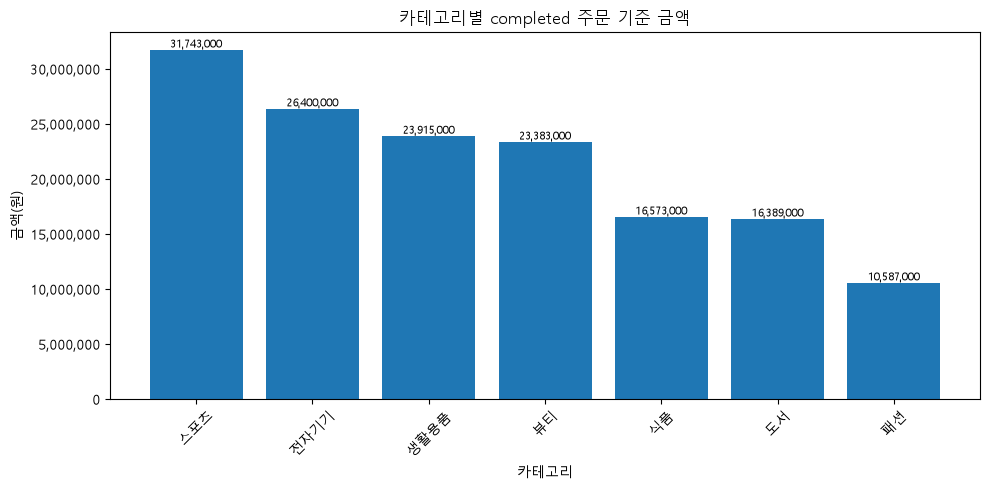

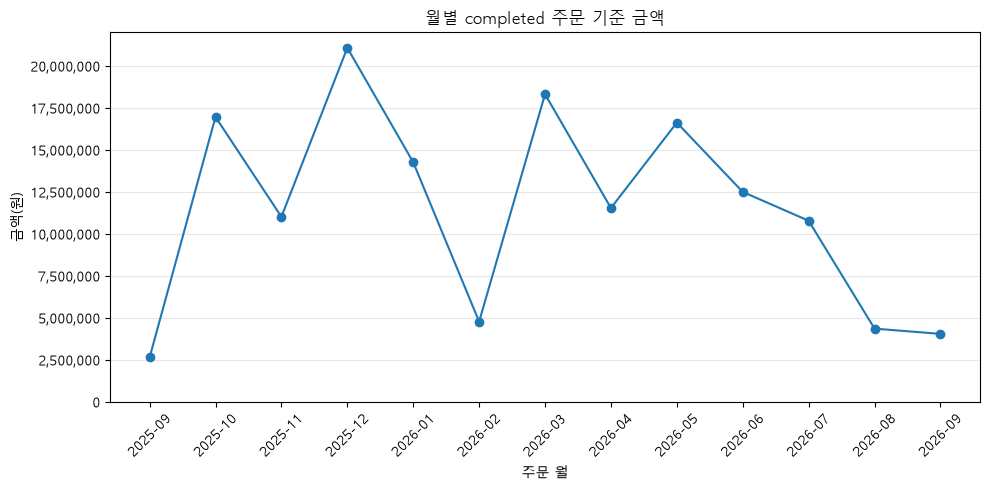

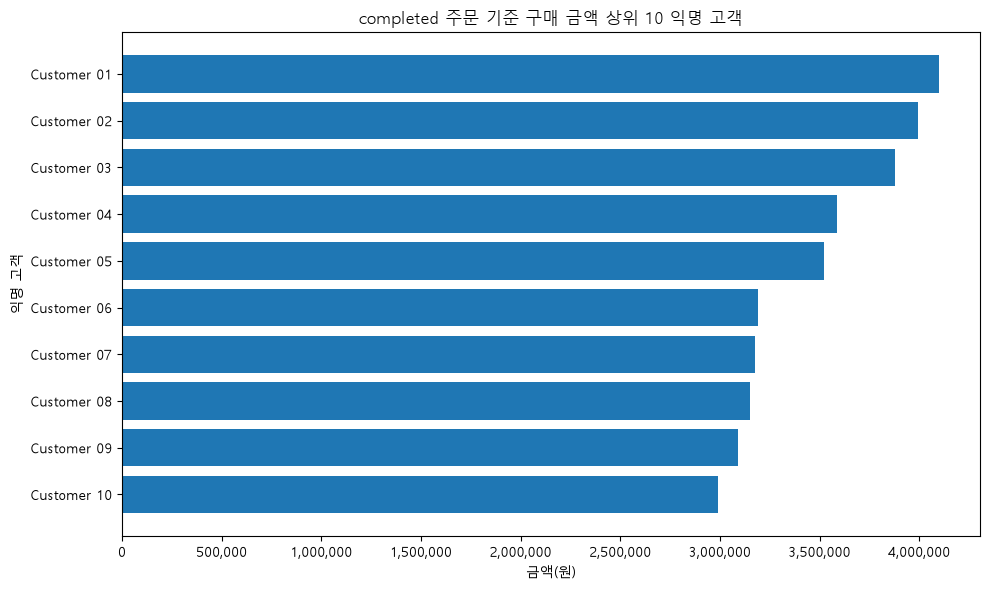

ch08_category_sales.png True 40109
ch08_monthly_sales.png True 81191
ch08_top_customers.png True 49415


In [14]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [15]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\dev\llm-data-analysis-study\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 질문

1. 카테고리별 completed 주문 기준 금액은 어떻게 다른가?
2. 월별 completed 주문 기준 금액과 주문 수는 어떻게 변하는가?
3. completed 주문 기준 구매 금액이 높은 고객은 어떤 특징을 보이는가?
4. 주문 상태별 주문 수는 어떻게 분포하는가?

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"` 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 다시 검증했습니다.
- `total_sales`는 completed 주문에 포함된 line_total 합계이며 회계상 순매출로 단정하지 않습니다.
- 주문 수는 `order_id`의 고유 개수(nunique)로 계산했습니다.
- 주문 상태별 주문 수는 전체 orders 기준입니다.
- 공개 고객 결과는 원본 고객 ID·이름 없이 순위 기반 익명 라벨을 사용했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
 

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [16]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/dev/llm-data-analysis-study/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [17]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


**1. 아직 확인하지 않은 분석 위험**

- 2025-09(15일부터)와 2026-09(14일까지)는 부분 월이라 월별 비교에서 낮게 보입니다. → 데이터 기간을 직접 확인함: 2025-09-15 ~ 2026-09-14 (반영)
- 월별 주문 수가 4~25건으로 작아서 고액 주문 몇 건만으로도 월 금액이 크게 바뀝니다. (반영: 한계에 기록)
- 순위 기반 익명 라벨은 데이터가 바뀌면 같은 라벨이 다른 고객을 가리킬 수 있습니다. (반영: 한계에 기록)
- 원본의 `signup_date`가 첫 주문일보다 늦은 경우 같은 논리 오류는 확인하지 않았습니다. (보류: 다음 분석)

**2. 과도한 해석이 될 수 있는 표현**

- "스포츠 카테고리가 가장 인기 있다" → "completed 주문 기준 금액이 가장 크다"로 수정
- "12월 매출이 연말 수요로 증가했다" → "2025-12의 completed 금액과 주문 수가 가장 높았다"로 수정 (원인 데이터 없음)
- "상위 고객은 충성 고객이다" → "구매 금액 상위 고객이며, 반복 구매형과 고액 단건형이 섞여 있다"로 수정

**3. 보고서에 반드시 적어야 할 계산 기준**

- 금액 = completed 주문의 `line_total = quantity × unit_price` 합계이며 회계상 순매출이 아님
- 주문 수 = `order_id.nunique()` (상세 행 474 ≠ 주문 184)
- 주문 상태 분포는 전체 orders 기준
- 공개 고객 결과는 순위 기반 익명 라벨, 원본 ID·이름 제외

**4. 추가로 필요한 검증**

- 카테고리 금액을 수량 × 평균 단가로 분해 (실습 셀에서 수량 1개당 금액을 계산해 일부 반영)
- 부분 월은 일 평균 금액으로 보정해 비교
- 월별 취소율·환불률 확인

**5. 데이터에 없는 원인은 추정하지 않기**

- 광고비, 프로모션, 원가, 만족도, 재고 데이터가 없으므로 금액 차이의 원인과 수익성은 결론에 쓰지 않았습니다.

## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


**1. 핵심 EDA 결과 3개와 판단 근거·한계**

| 결과                         | 핵심 수치                                                             | 판단 근거                                                                                                    | 한계                                                         |
| ---------------------------- | --------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------ | ------------------------------------------------------------ |
| 카테고리별 completed 금액    | 스포츠 31,743,000원(21.31%) 1위, 패션 7.11% 최하위, 상위 4개가 70.77% | 스포츠는 수량(295)도 1위라 단가보다 수량 영향이 큼. 식품은 수량 133개지만 1개당 금액 124,609원으로 가장 높음 | 원가가 없어 수익성 판단 불가, 선호도를 뜻하지 않음           |
| 월별 completed 금액·주문 수 | 최고 2025-12 21,085,000원(23건), 최저 2025-09 2,650,000원(5건)        | 금액이 주문당 금액보다 주문 수와 비슷하게 움직임                                                             | 1년치라 계절성 판단 불가, 양 끝 월은 부분 월                 |
| 고객별 completed 구매 금액   | 구매 고객 100명, 상위 10명 비중 23.29%, 1회 구매 고객 44명            | 상위 고객에 반복 구매형(4~5회)과 고액 단건형(2회, 주문당 약 150만 원 이상)이 섞여 있음                       | 최근 구매일 미반영, completed 주문이 없는 고객 50명은 제외됨 |

**2. 대표 그래프와 집계값 일치**

- 그래프 3개는 검증된 집계표(`category_sales`, `monthly_sales`, `customer_sales_public`)를 그대로 입력으로 사용했습니다.
- 그래프 입력값과 저장된 CSV를 `np.allclose()`로 비교한 결과 카테고리·월별 모두 `True`입니다.
- 그래프의 최대 카테고리(스포츠 31,743,000)와 최고·최저 월(2025-12 / 2025-09)이 표의 값과 같습니다.

**3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv` 확인**

- total consistency: completed_source, category, monthly, customer 모두 148,990,000원, 차이 0, 4개 모두 PASS
- project validation: 8개 항목 모두 PASS

**4. 공개 고객 CSV 개인정보 재확인**

- 저장된 CSV를 다시 읽은 결과 컬럼은 `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`입니다.
- 금지 컬럼은 0개이고, 라벨은 모두 `Customer NN` 형식입니다 → PASS

**5. LLM 사용 기록**

- 위 17번 답변과 본문 "9. LLM 활용 기록"에 목적, Prompt 요약, 제안, 반영 여부, 사람이 검증한 근거를 적었습니다.

**6. 전체 재실행과 수치 비교**

- `python scripts/run_midterm_project.py` 종료 코드 0, 최종 Validation 모두 PASS
- Notebook과 스크립트의 completed·category·monthly·customer 합계와 Validation 결과가 5개 항목 모두 같습니다(`same=True`).



In [19]:
completed_src = analysis_tables["completed_order_sales"]
completed_total = float(completed_src["line_total"].sum())
my_totals = {
    "category": float(category_sales["total_sales"].sum()),
    "monthly": float(monthly_sales["total_sales"].sum()),
    "customer": float(customer_sales_internal["total_sales"].sum()),
}
print(f"completed source total: {completed_total:,.0f}")
for name, value in my_totals.items():
    print(f"{name:9s}: {value:,.0f}  일치={np.isclose(completed_total, value)}")

print("\n주문 상세 행 수 vs 주문 수 (completed)")
print("  detail rows :", len(completed_src))
print("  order_id 수 :", completed_src["order_id"].nunique())

cat = category_sales.copy()
cat["avg_unit_amount"] = (cat["total_sales"] / cat["total_quantity"]).round(0)
display(cat)

top10_share = customer_sales_public.head(10)["total_sales"].sum() / completed_total * 100
print(f"구매 고객 수: {len(customer_sales_public)}명, 상위 10명 금액 비중: {top10_share:.2f}%")
display(customer_sales_public["order_count"].value_counts().sort_index().rename("customers"))

saved_tc = pd.read_csv(REPORT_DIR / "ch08_total_consistency_check.csv")
display(saved_tc)
assert saved_tc["status"].eq("PASS").all()

completed source total: 148,990,000
category : 148,990,000  일치=True
monthly  : 148,990,000  일치=True
customer : 148,990,000  일치=True

주문 상세 행 수 vs 주문 수 (completed)
  detail rows : 474
  order_id 수 : 184


,category,total_quantity,total_sales,sales_ratio,avg_unit_amount
0,스포츠,295,31743000,21.31,107603.0
1,전자기기,259,26400000,17.72,101931.0
2,생활용품,272,23915000,16.05,87923.0
3,뷰티,223,23383000,15.69,104857.0
4,식품,133,16573000,11.12,124609.0
5,도서,149,16389000,11.00,109993.0
6,패션,111,10587000,7.11,95378.0


구매 고객 수: 100명, 상위 10명 금액 비중: 23.29%


order_count
1    44
2    37
3    12
4     5
5     2
Name: customers, dtype: int64

,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


In [20]:
import shutil
import matplotlib.pyplot as plt
from src.visualization import setup_korean_font

setup_korean_font()
SUBMIT_IMG_DIR = PROJECT_ROOT / "notebooks" / "ch08" / "images"
SUBMIT_IMG_DIR.mkdir(parents=True, exist_ok=True)

saved_cat = pd.read_csv(REPORT_DIR / "ch08_category_sales.csv")
saved_month = pd.read_csv(REPORT_DIR / "ch08_monthly_sales.csv")
print("그래프1(카테고리) 입력 = 저장 CSV:",
      np.allclose(category_sales["total_sales"].values, saved_cat["total_sales"].values))
print("그래프2(월별) 입력 = 저장 CSV:",
      np.allclose(monthly_sales["total_sales"].values, saved_month["total_sales"].values))
print("최대 카테고리:", category_sales.iloc[0]["category"], f'{category_sales.iloc[0]["total_sales"]:,.0f}')
peak = monthly_sales.loc[monthly_sales["total_sales"].idxmax()]
low = monthly_sales.loc[monthly_sales["total_sales"].idxmin()]
print("최대 월:", peak["order_month"], f'{peak["total_sales"]:,.0f}', "/ 최소 월:", low["order_month"], f'{low["total_sales"]:,.0f}')

shutil.copy(FIGURE_DIR / "ch08_category_sales.png", SUBMIT_IMG_DIR / "graph01.png")
shutil.copy(FIGURE_DIR / "ch08_monthly_sales.png", SUBMIT_IMG_DIR / "graph02.png")
shutil.copy(FIGURE_DIR / "ch08_top_customers.png", SUBMIT_IMG_DIR / "graph03.png")


def save_table_image(tables, path, title):
    """검증 표를 Evidence 이미지로 저장합니다."""
    heights = [0.45 + 0.32 * (len(df) + 1) for _, df in tables]
    fig, axes = plt.subplots(len(tables), 1, figsize=(12, sum(heights) + 0.6),
                             gridspec_kw={"height_ratios": heights})
    axes = np.atleast_1d(axes)
    for ax, (sub, df) in zip(axes, tables):
        ax.axis("off")
        ax.set_title(sub, loc="left", fontsize=11, fontweight="bold")
        tbl = ax.table(cellText=df.astype(str).values, colLabels=df.columns, loc="center", cellLoc="center")
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        for (r, _), cell in tbl.get_celld().items():
            if r == 0:
                cell.set_facecolor("#e8eef7")
            if cell.get_text().get_text() == "PASS":
                cell.set_facecolor("#dff3e3")
            elif cell.get_text().get_text() == "FAIL":
                cell.set_facecolor("#f8d7da")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


save_table_image(
    [("원본 데이터 개요 (data/raw)", dataset_summary),
     ("전처리 전후 비교", preprocessing_comparison),
     ("PK 검증", key_duplicate_checks.drop(columns="detail")),
     ("FK 검증", relationship_checks)],
    SUBMIT_IMG_DIR / "step02_data_validation.png",
    "STEP 02 입력 데이터·전처리·PK/FK 검증",
)
print(sorted(p.name for p in SUBMIT_IMG_DIR.iterdir()))

그래프1(카테고리) 입력 = 저장 CSV: True
그래프2(월별) 입력 = 저장 CSV: True
최대 카테고리: 스포츠 31,743,000
최대 월: 2025-12 21,085,000 / 최소 월: 2025-09 2,650,000
['graph01.png', 'graph02.png', 'graph03.png', 'nb_cell27_1.png', 'nb_cell27_2.png', 'nb_cell27_3.png', 'step02_data_validation.png', 'step06_reproduce.png']


In [21]:
import subprocess

saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")
print("공개 고객 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", sorted(FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)))
print("라벨 형식 OK:", saved_customer["customer_label"].str.fullmatch(r"Customer \d{2,}").all())

run = subprocess.run(
    [sys.executable, "scripts/run_midterm_project.py"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, encoding="utf-8",
    env={**__import__("os").environ, "PYTHONIOENCODING": "utf-8"},
)
print("스크립트 종료 코드:", run.returncode)
print(run.stdout.split("[최종 Validation]")[1].split("[카테고리별")[0] if run.returncode == 0 else run.stderr)

script_validation = pd.read_csv(REPORT_DIR / "ch08_project_validation.csv")
script_tc = pd.read_csv(REPORT_DIR / "ch08_total_consistency_check.csv")
compare = pd.DataFrame({
    "item": ["completed_total", "category_total", "monthly_total", "customer_total", "validation_all_pass"],
    "notebook": [completed_total, *my_totals.values(), bool(project_validation["status"].eq("PASS").all())],
    "script": [*script_tc["amount"].tolist(), bool(script_validation["status"].eq("PASS").all())],
})
compare["same"] = compare["notebook"] == compare["script"]
display(compare)
assert run.returncode == 0 and compare["same"].all()

save_table_image(
    [("python scripts/run_midterm_project.py → reports/ch08_project_validation.csv", script_validation),
     ("Notebook vs Script 핵심 수치 비교", compare.astype(str))],
    SUBMIT_IMG_DIR / "step06_reproduce.png",
    "STEP 06 전체 프로젝트 재실행 확인",
)
print("Chapter 08 Final Validation: PASS")

공개 고객 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
라벨 형식 OK: True
스크립트 종료 코드: 0

                                 check                value             expected status
                          pk_integrity             all PASS             all PASS   PASS
                          fk_integrity                    0                    0   PASS
                     merge_checks_pass             all PASS             all PASS   PASS
                line_total_consistency                    0                    0   PASS
           completed_total_consistency            all match            all match   PASS
          category_sales_ratio_pct_sum                100.0                100.0   PASS
completed_rows_with_invalid_order_date                    0                    0   PASS
          public_customer_columns_safe no forbidden columns no forbidden columns   PASS




,item,notebook,script,same
0,completed_total,148990000.0,148990000.0,True
1,category_total,148990000.0,148990000.0,True
2,monthly_total,148990000.0,148990000.0,True
3,customer_total,148990000.0,148990000.0,True
4,validation_all_pass,True,True,True


Chapter 08 Final Validation: PASS


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```
